# Clustering Track — PriceRunner Aggregate Dataset

This notebook implements the two clustering algorithms required by the capstone:

1. **K-Means Clustering**
2. **Agglomerative Hierarchical Clustering**

The dataset is `pricerunner_aggreagte.csv`. The feature-selection step uses available numeric
columns and excludes identifier/label columns so that clustering remains unsupervised.


## 1. Imports and reproducibility

All preprocessing is performed before fitting. K-Means uses a fixed random seed so its labels
are reproducible.


In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
N_CLUSTERS = 6
DATASET_NAME = "pricerunner_aggreagte.csv"
pd.set_option("display.max_columns", 20)


## 2. Load and inspect the PriceRunner dataset

The path resolution supports running this notebook from either the project root or the
`notebooks` directory. The exact requested filename is used.


In [22]:
notebook_dir = Path.cwd()
candidate_paths = [
    notebook_dir / DATASET_NAME,
    notebook_dir / "data" / DATASET_NAME,
    notebook_dir.parent / DATASET_NAME,
    notebook_dir.parent / "data" / DATASET_NAME,
    notebook_dir.parent.parent / DATASET_NAME,
    notebook_dir.parent.parent / "data" / DATASET_NAME,
]
dataset_path = next((path for path in candidate_paths if path.exists()), None)
if dataset_path is None:
    # Also check the correctly spelled filename and nested project directories.
    filename_options = {
        DATASET_NAME,
        DATASET_NAME.replace("aggreagte", "aggregate"),
    }
    search_roots = {
        notebook_dir,
        notebook_dir.parent,
        notebook_dir.parent.parent,
    }

    recursive_candidates = [
        path
        for root in search_roots
        if root.exists()
        for path in root.rglob("*.csv")
        if path.name in filename_options
    ]

    dataset_path = next(
        (path for path in [*candidate_paths, *recursive_candidates] if path.exists()),
        None,
    )

    if dataset_path is None:
        raise FileNotFoundError(
            f"Could not find {DATASET_NAME} or its correctly spelled variant "
            f"({DATASET_NAME.replace('aggreagte', 'aggregate')}). "
            "Add the CSV file to the project root, data/, or notebooks/ directory."
        )

df = pd.read_csv(dataset_path)
print(f"Loaded: {dataset_path}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
display(df.head())
display(df.dtypes.rename("dtype").to_frame())


Loaded: c:\Projects\AutoML-_-Project\gas_sensor_ml_capstone\data\pricerunner_aggregate.csv
Shape: 35,311 rows x 7 columns


,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


,dtype
Product ID,int64
Product Title,object
Merchant ID,int64
Cluster ID,int64
Cluster Label,object
Category ID,int64
Category Label,object


## 3. Prepare numeric features for unsupervised learning

PriceRunner files commonly contain identifiers, category labels, and product text alongside
numeric attributes. Clustering is fitted only on usable numeric measurements. Columns whose
names indicate identifiers or labels are excluded when possible; if that would remove every
numeric column, the notebook falls back to all numeric columns.

Missing values are median-imputed and features are standardized so distance-based algorithms
are comparable across columns.


In [23]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
excluded_name_parts = (
    "id",
    "label",
    "cluster",
    "category",
    "class",
    "target",
    "index",
)
feature_columns = [
    column
    for column in numeric_columns
    if not any(part in column.lower() for part in excluded_name_parts)
]
if not feature_columns:
    feature_columns = numeric_columns
if not feature_columns:
    raise ValueError("The dataset contains no numeric columns suitable for clustering.")

X_raw = df[feature_columns].replace([np.inf, -np.inf], np.nan)
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_imputed = imputer.fit_transform(X_raw)
X_scaled = scaler.fit_transform(X_imputed)

print(f"Numeric columns found: {len(numeric_columns)}")
print(f"Features used for clustering ({len(feature_columns)}): {feature_columns}")
print(f"Feature matrix shape: {X_scaled.shape}")
print(f"Missing values after imputation: {int(np.isnan(X_scaled).sum())}")


Numeric columns found: 4
Features used for clustering (4): ['Product ID', ' Merchant ID', ' Cluster ID', ' Category ID']
Feature matrix shape: (35311, 4)
Missing values after imputation: 0


## 4. Select a common cluster count

Both required algorithms use the same cluster count for a fair comparison. Six is the default
for this PriceRunner analysis and can be changed in the configuration cell if the project team
has a documented domain-specific choice.


In [24]:
if len(X_scaled) <= N_CLUSTERS:
    raise ValueError(
        f"The dataset must contain more than {N_CLUSTERS} rows; found {len(X_scaled)}."
    )
print(f"Common cluster count: {N_CLUSTERS}")


Common cluster count: 6


## 5. K-Means Clustering

K-Means assigns each observation to a centroid and returns one cluster label per observation.


In [25]:
kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    init="k-means++",
    n_init=10,
    random_state=RANDOM_STATE,
)
kmeans_labels = kmeans.fit_predict(X_scaled)
df["kmeans_cluster"] = kmeans_labels

print("K-Means fitted successfully.")
print(f"Labels obtained: {len(kmeans_labels):,}")
display(df["kmeans_cluster"].value_counts().sort_index().rename("samples").to_frame())


K-Means fitted successfully.
Labels obtained: 35,311


,samples
kmeans_cluster,
0,4081
1,6668
2,4999
3,7711
4,7426
5,4426


## 6. Agglomerative Hierarchical Clustering

Agglomerative clustering repeatedly merges the closest groups. Ward linkage minimizes the
increase in within-cluster variance at each merge.


In [26]:
hierarchical = AgglomerativeClustering(
    n_clusters=N_CLUSTERS,
    linkage="ward",
)
hierarchical_labels = hierarchical.fit_predict(X_scaled)
df["hierarchical_cluster"] = hierarchical_labels

print("Agglomerative Hierarchical Clustering fitted successfully.")
print(f"Labels obtained: {len(hierarchical_labels):,}")
display(
    df["hierarchical_cluster"]
    .value_counts()
    .sort_index()
    .rename("samples")
    .to_frame()
)


Agglomerative Hierarchical Clustering fitted successfully.
Labels obtained: 35,311


,samples
hierarchical_cluster,
0,7463
1,7080
2,7426
3,5124
4,4137
5,4081


## 7. Confirm both required algorithms produced labels

These checks verify that both estimators fitted successfully and assigned one non-missing
label to every PriceRunner record.


In [27]:
label_summary = pd.DataFrame(
    {
        "algorithm": ["K-Means", "Agglomerative Hierarchical"],
        "n_samples": [len(kmeans_labels), len(hierarchical_labels)],
        "n_clusters_obtained": [
            np.unique(kmeans_labels).size,
            np.unique(hierarchical_labels).size,
        ],
        "missing_labels": [
            int(pd.isna(kmeans_labels).sum()),
            int(pd.isna(hierarchical_labels).sum()),
        ],
    }
)
display(label_summary)

assert len(kmeans_labels) == len(df)
assert len(hierarchical_labels) == len(df)
assert np.unique(kmeans_labels).size == N_CLUSTERS
assert np.unique(hierarchical_labels).size == N_CLUSTERS
assert not pd.isna(kmeans_labels).any()
assert not pd.isna(hierarchical_labels).any()
print("Both required clustering algorithms fitted successfully and produced complete labels.")


,algorithm,n_samples,n_clusters_obtained,missing_labels
0,K-Means,35311,6,0
1,Agglomerative Hierarchical,35311,6,0


Both required clustering algorithms fitted successfully and produced complete labels.


## 8. Unsupervised evaluation summary

The three required clustering metrics are reported for both algorithms. Higher silhouette and
Calinski–Harabasz scores are generally better; a lower Davies–Bouldin score is better.


In [28]:
evaluation = pd.DataFrame(
    [
        {
            "algorithm": "K-Means",
            "silhouette_score": silhouette_score(X_scaled, kmeans_labels),
            "davies_bouldin_index": davies_bouldin_score(X_scaled, kmeans_labels),
            "calinski_harabasz_index": calinski_harabasz_score(
                X_scaled, kmeans_labels
            ),
        },
        {
            "algorithm": "Agglomerative Hierarchical",
            "silhouette_score": silhouette_score(X_scaled, hierarchical_labels),
            "davies_bouldin_index": davies_bouldin_score(
                X_scaled, hierarchical_labels
            ),
            "calinski_harabasz_index": calinski_harabasz_score(
                X_scaled, hierarchical_labels
            ),
        },
    ]
)
display(evaluation.round(4))


,algorithm,silhouette_score,davies_bouldin_index,calinski_harabasz_index
0,K-Means,0.5510,0.6408,101946.7150
1,Agglomerative Hierarchical,0.5161,0.6999,89010.4082


## 9. K-Means Elbow Curve

The elbow curve compares inertia for several values of `k`. The selected value is marked so the choice is transparent and reproducible.


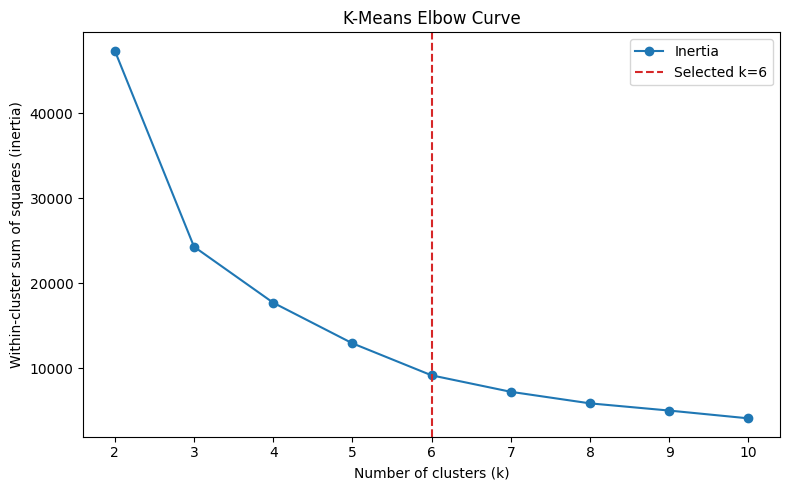

In [29]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage

k_values = range(2, min(11, len(X_scaled)))
inertias = []
for k in k_values:
    elbow_model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=RANDOM_STATE,
    )
    elbow_model.fit(X_scaled)
    inertias.append(elbow_model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o", color="tab:blue", label="Inertia")
plt.axvline(N_CLUSTERS, color="tab:red", linestyle="--", label=f"Selected k={N_CLUSTERS}")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares (inertia)")
plt.title("K-Means Elbow Curve")
plt.xticks(list(k_values))
plt.legend()
plt.tight_layout()
plt.show()


## 10. Hierarchical Clustering Dendrogram

A full dendrogram is impractical for a large dataset, so a reproducible sample is used for visualization. The clustering algorithm itself was fitted on all observations above.


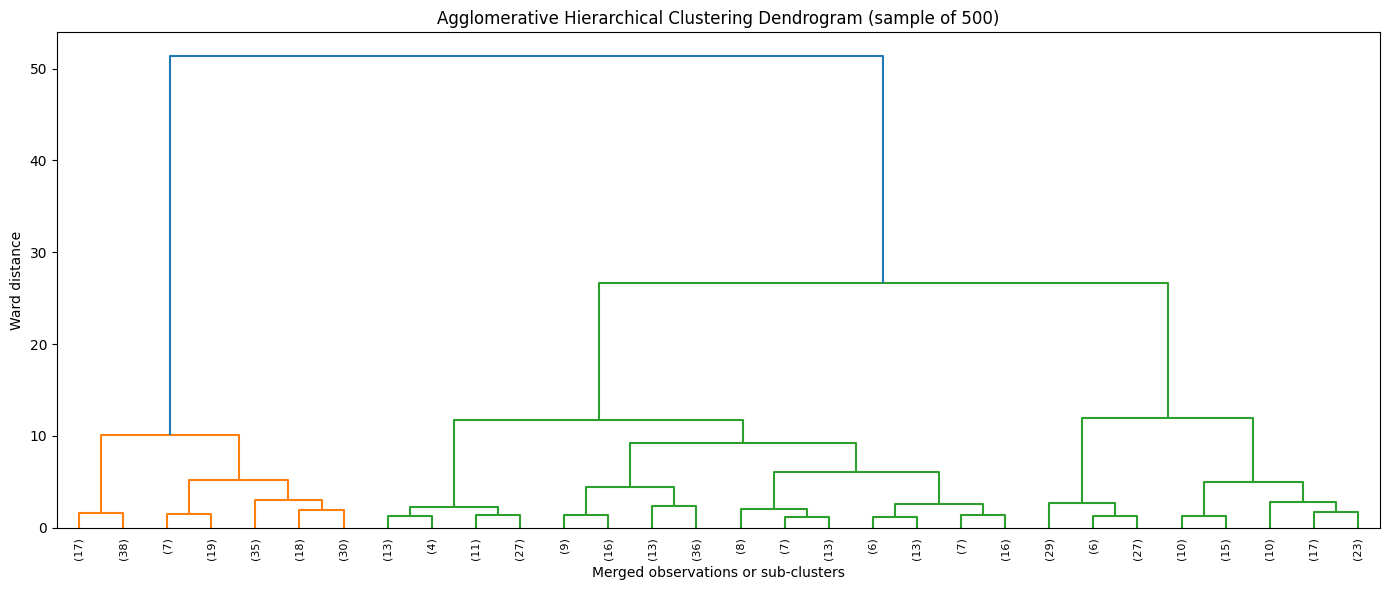

In [30]:
dendrogram_sample_size = min(500, len(X_scaled))
rng = np.random.default_rng(RANDOM_STATE)
dendrogram_indices = rng.choice(len(X_scaled), size=dendrogram_sample_size, replace=False)
X_dendrogram = X_scaled[dendrogram_indices]

hierarchy_linkage = linkage(X_dendrogram, method="ward")
plt.figure(figsize=(14, 6))
dendrogram(
    hierarchy_linkage,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=8,
)
plt.xlabel("Merged observations or sub-clusters")
plt.ylabel("Ward distance")
plt.title(f"Agglomerative Hierarchical Clustering Dendrogram (sample of {dendrogram_sample_size})")
plt.tight_layout()
plt.show()


## 11. PCA Cluster Visualizations

PCA reduces the standardized feature matrix to two dimensions for visualization only. It does not replace the original feature matrix used for fitting.


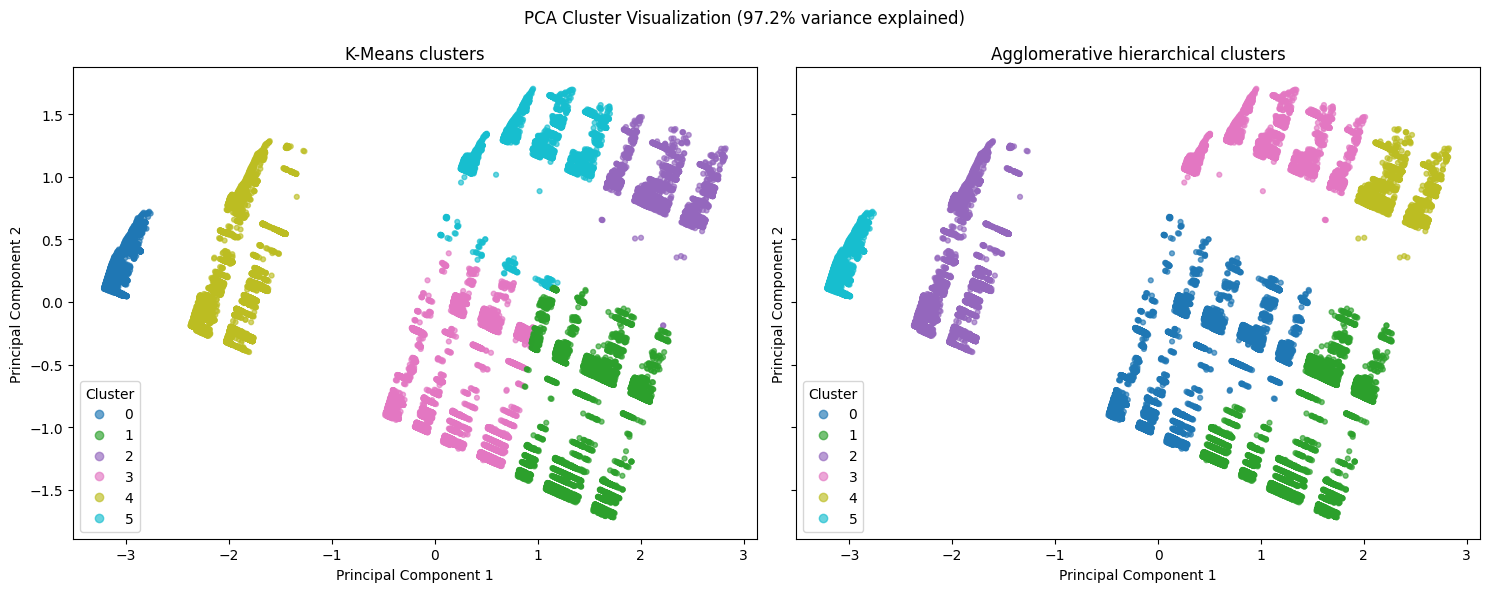

In [31]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
explained_variance = pca.explained_variance_ratio_.sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for axis, labels, title in [
    (axes[0], kmeans_labels, "K-Means clusters"),
    (axes[1], hierarchical_labels, "Agglomerative hierarchical clusters"),
]:
    scatter = axis.scatter(
        X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", s=12, alpha=0.65
    )
    axis.set_title(title)
    axis.set_xlabel("Principal Component 1")
    axis.set_ylabel("Principal Component 2")
    axis.legend(*scatter.legend_elements(), title="Cluster", loc="best")

fig.suptitle(f"PCA Cluster Visualization ({explained_variance:.1%} variance explained)")
fig.tight_layout()
plt.show()


## 12. t-SNE Visualization

A t-SNE projection is shown for K-Means labels. To keep notebook execution practical, at most 2,000 observations are sampled reproducibly.


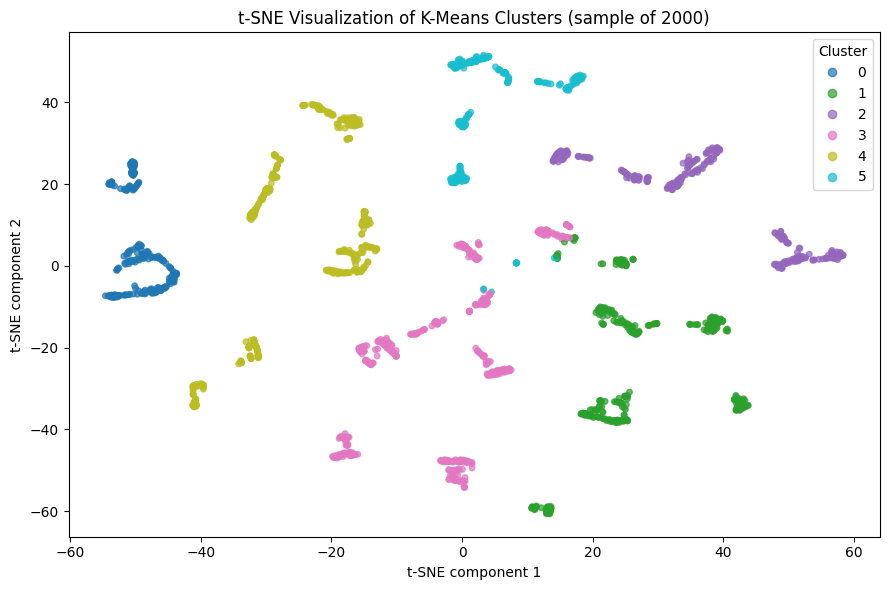

In [32]:
tsne_sample_size = min(2000, len(X_scaled))
tsne_indices = rng.choice(len(X_scaled), size=tsne_sample_size, replace=False)
tsne_perplexity = min(30, max(5, (tsne_sample_size - 1) // 3))
X_tsne = TSNE(
    n_components=2,
    perplexity=tsne_perplexity,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
).fit_transform(X_scaled[tsne_indices])

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=kmeans_labels[tsne_indices],
    cmap="tab10",
    s=16,
    alpha=0.7,
)
plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")
plt.title(f"t-SNE Visualization of K-Means Clusters (sample of {tsne_sample_size})")
plt.legend(*scatter.legend_elements(), title="Cluster", loc="best")
plt.tight_layout()
plt.show()
